# NEAT g94 line follower · reproduce the four results figures

This notebook contains the data and plotting code for the learning curve, test completion, paired speed and tracking error, and two zigzag trajectories. The original PNGs are already visible below. Select **Run All** in a Python 3.11+ Jupyter kernel with Matplotlib, NumPy, and Pillow to regenerate them. The original render used Matplotlib 3.11.2.

The source is the completed `neat-corner-100-20261104` experiment. The plots use the saved champion logs, 450 paired test episodes on 90 tracks, and six chassis traces on two example tracks. The data cell embeds the columns used by the notebook and the two track masks. It makes the file portable without a checkout, a model file, or a MuJoCo installation.

For PNG and SVG exports, set `EXPORT_DIR = Path("plots")` in the setup cell.

In [1]:
import base64
import gzip
from io import BytesIO
import json
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
import numpy as np
from PIL import Image as PILImage

EXPORT_DIR = None

PAPER, INK, MUTED, GRID = "#faf9f6", "#182637", "#4c5c6d", "#e1e3e3"
POLICIES = {
    "neat-fresh": ("NEAT g94", "#6743a4"),
    "neat-g109": ("NEAT g109", "#657281"),
    "pid-filtered": ("Filtered PID", "#3976a9"),
    "pid-supervised-original": ("Supervised PID", "#9e641b"),
    "pid-supervised-tuned": ("Tuned supervised PID", "#087e6c"),
}
LEVELS = ("beginner", "intermediate", "advanced")
plt.rcParams.update({"font.family": "DejaVu Sans", "text.color": INK, "font.size": 10,
                     "axes.facecolor": PAPER, "axes.labelcolor": INK, "axes.titlesize": 11,
                     "axes.titleweight": "bold", "axes.edgecolor": GRID, "axes.spines.top": False,
                     "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
                     "svg.fonttype": "none"})


def completed(row):
    return row["completed"] == "True"


def page(number, title, subtitle, footer, size=(12, 5.1)):
    fig = plt.figure(figsize=size, facecolor=PAPER)
    fig.text(.045, .958, f"MUJOCO LINE FOLLOWING  /  MATCHED BENCHMARK  /  {number:02}",
             fontsize=9, color=MUTED, weight="bold", va="top")
    fig.text(.045, .905, title, fontsize=23, weight="bold", va="top")
    fig.text(.045, .817 if size[1] < 6 else .842, subtitle, fontsize=11, color=MUTED, va="top")
    fig.text(.045, .039, footer, fontsize=9, color=MUTED, va="bottom")
    return fig


def save(fig, name):
    # Render at the report's DPI and send the original-size PNG to the notebook.
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=190)
    png = buffer.getvalue()
    if EXPORT_DIR is not None:
        EXPORT_DIR.mkdir(parents=True, exist_ok=True)
        (EXPORT_DIR / f"{name}.png").write_bytes(png)
        fig.savefig(EXPORT_DIR / f"{name}.svg", dpi=190)
    plt.close(fig)
    display({"image/png": base64.b64encode(png).decode("ascii"), "text/plain": name},
            raw=True, metadata={"image/png": {"width": 960}})

## Data and track pairing

The embedded JSON stores the generation scores and stages, one test record per controller and track, and the selected trace data. A track slot identifies the course within this test suite. The geometry hashes confirm that the records line up across controllers. The trace columns are time in seconds, world X and Y in meters, and route progress as a fraction.

In [2]:
# Embedded gzip-compressed JSON. Expand this cell to see the payload.
EMBEDDED_DATA = (
    '...'
    'qEzCgb7/6p9//r3/+w8kTwoMIm8OAA=='
)

In [3]:
data = json.loads(gzip.decompress(base64.b64decode(EMBEDDED_DATA)))
generations = data["generations"]
curriculum = data["curriculum"]
selected = data["selected_generation"]
example_tracks = data["example_tracks"]

episodes = data["episodes"]
rows = {policy: sorted((r for r in episodes if r["policy_id"] == policy),
                       key=lambda r: int(r["track_slot"])) for policy in POLICIES}
track_hashes = [r["track_hash"] for r in rows["neat-fresh"]]
assert len(episodes) == 450 and len(set(track_hashes)) == 90
assert all([r["track_hash"] for r in records] == track_hashes for records in rows.values())

## 1. Validation learning curve

The thin line is the fraction of 30 validation tracks finished by each generation's champion. The purple step line takes the cumulative maximum of those fractions. The marker shows the selected checkpoint. The bands show the difficulty of the procedural training course, and the lower panel shows the drill stage.

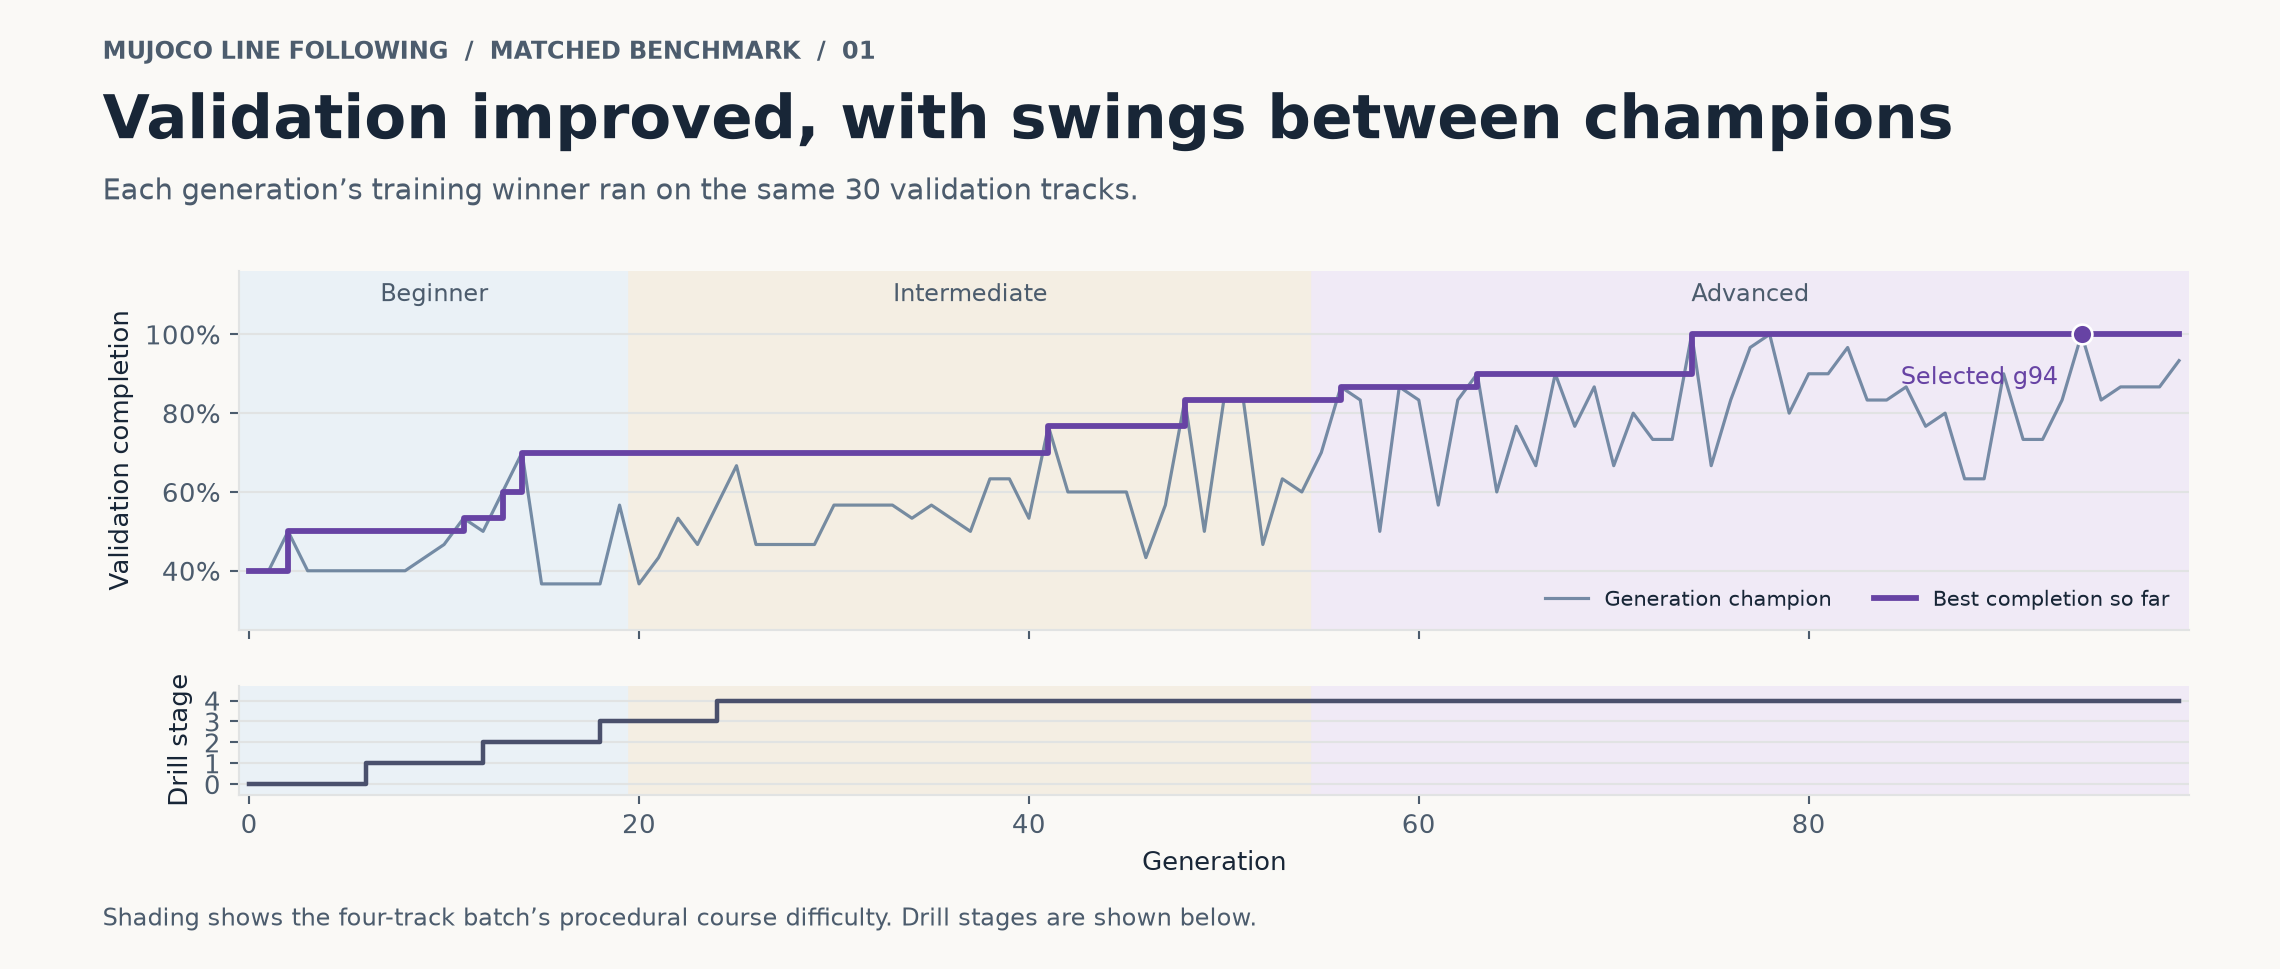

In [4]:
def learning_plot(generations, curriculum, selected):
    x = np.arange(len(generations))
    completion = 100 * np.array([float(r["validation_completion_rate"]) for r in generations])
    color = POLICIES["neat-fresh"][1]
    fig = page(1, "Validation improved, with swings between champions",
               "Each generation’s training winner ran on the same 30 validation tracks.",
               "Shading shows the four-track batch’s procedural course difficulty. Drill stages are shown below.")
    upper, lower = fig.add_gridspec(2, 1, left=.105, right=.96, top=.72, bottom=.18, hspace=.24,
                                   height_ratios=(3.3, 1)).subplots(sharex=True)
    for start, stop, tint, label in ((0, 20, "#eaf1f6", "Beginner"), (20, 55, "#f4eee3", "Intermediate"),
                                     (55, 100, "#f0eaf6", "Advanced")):
        for ax in (upper, lower):
            ax.axvspan(start-.5, stop-.5, color=tint, zorder=0)
        upper.text((start+stop-1)/2, 110, label, ha="center", va="center", color=MUTED, fontsize=9)
    upper.plot(x, completion, lw=1.2, color="#536f8e", alpha=.78, label="Generation champion")
    upper.step(x, np.maximum.accumulate(completion), where="post", lw=2.2, color=color, label="Best completion so far")
    upper.scatter([selected], [completion[selected]], color=color, s=56, edgecolor="white", zorder=5)
    upper.annotate(f"Selected g{selected}", (selected, completion[selected]), xytext=(-9, -12),
                   textcoords="offset points", ha="right", va="top", color=color, fontsize=9)
    upper.set(ylabel="Validation completion", ylim=(25, 116), yticks=(40, 60, 80, 100))
    upper.yaxis.set_major_formatter(PercentFormatter(100))
    upper.legend(loc="lower right", frameon=False, ncol=2, fontsize=8)
    lower.step(x, [int(r["stage"]) for r in curriculum], where="post", color="#4a506c", lw=1.7)
    lower.set(ylabel="Drill stage", xlabel="Generation", xlim=(-.5, 99.5), ylim=(-.5, 4.7), yticks=range(5))
    for ax in (upper, lower):
        ax.grid(axis="y", color=GRID, lw=.8)
    save(fig, "01-learning")

learning_plot(generations, curriculum, selected)

## 2. Final test completion

Count completed episodes within each controller and track group. Bar heights show the fraction completed, while labels show the raw counts. Zigzag membership comes from the course tags and overlaps the difficulty groups.

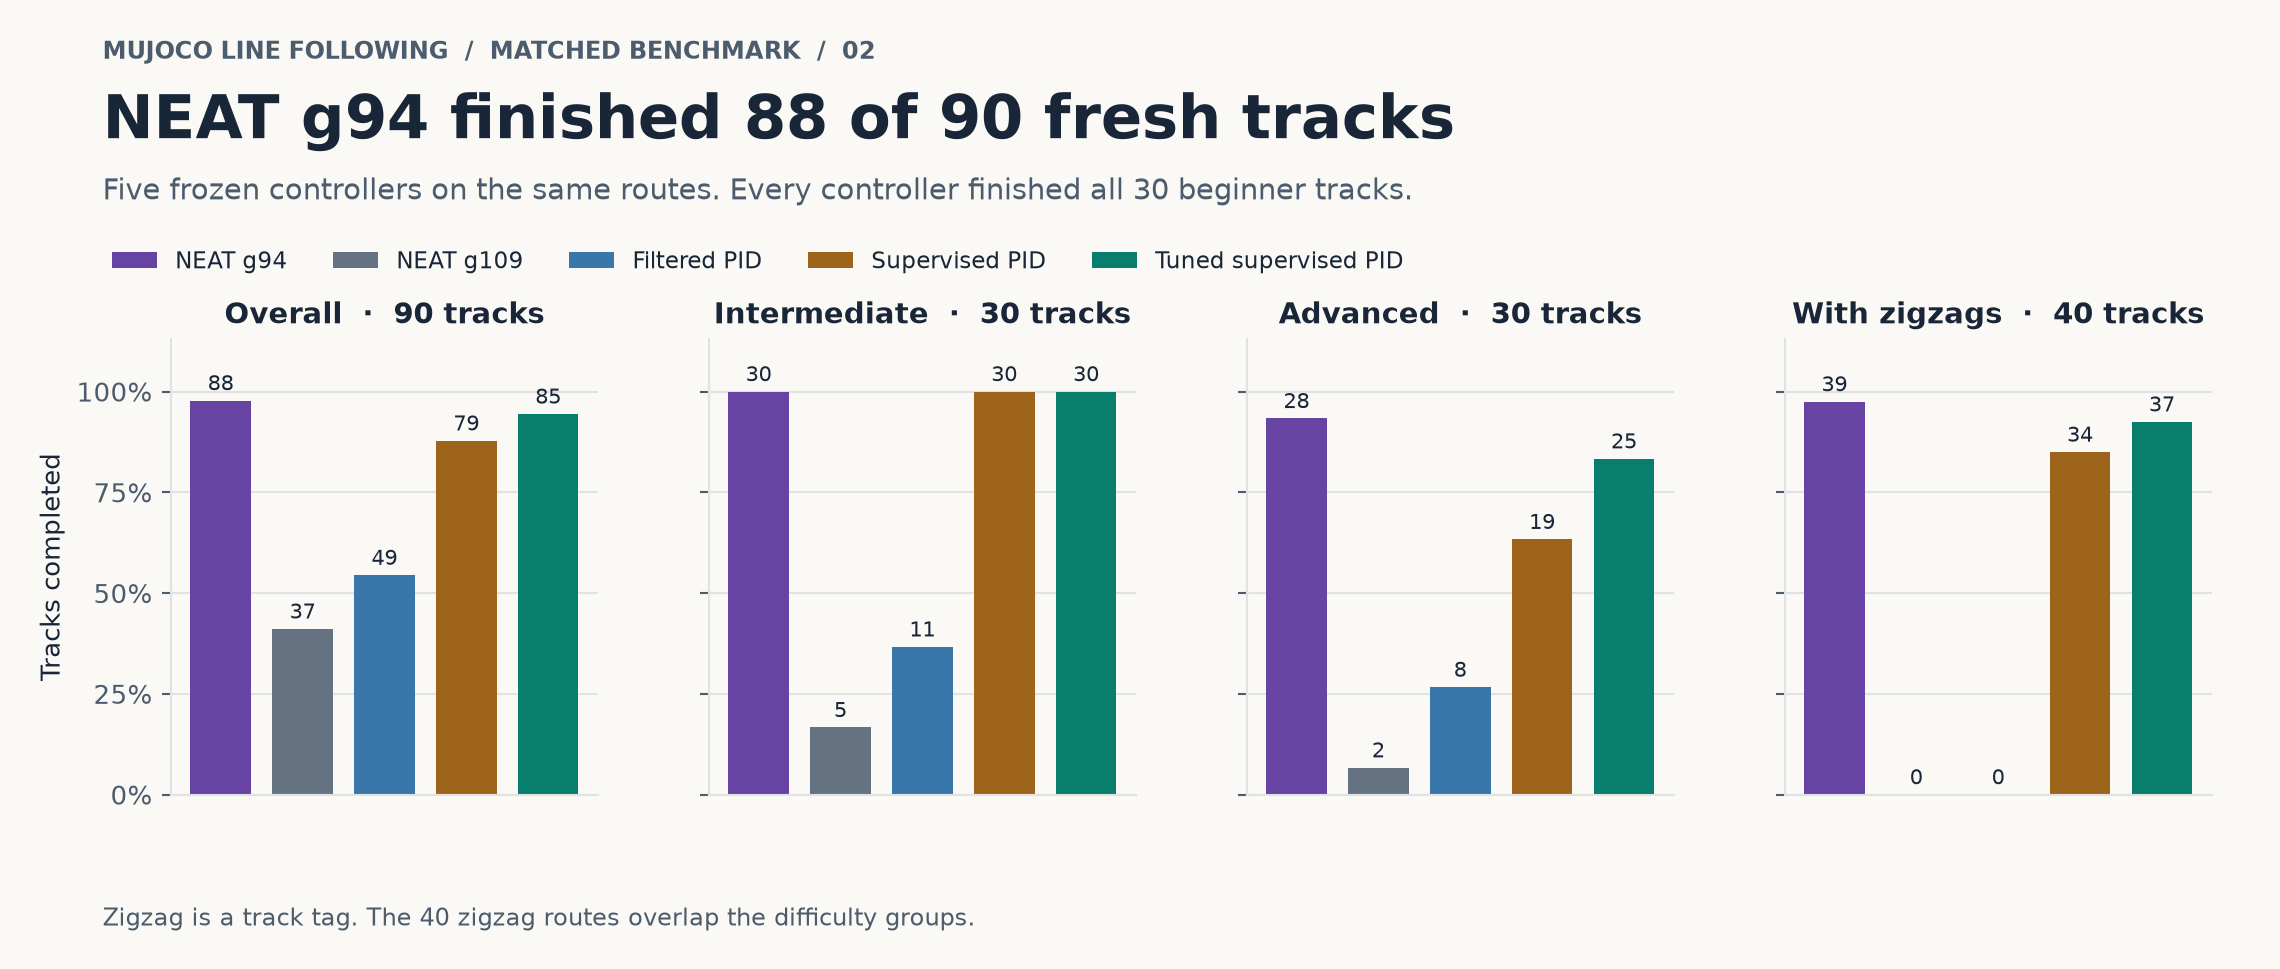

In [5]:
def completion_counts(rows):
    summary = []
    for policy, records in rows.items():
        for subset in ("all", *LEVELS, "zigzag"):
            sample = [r for r in records if subset in {"all", r["difficulty"]}
                      or subset == "zigzag" and "zigzag" in r["features"].split(";")]
            summary.append({"policy": policy, "subset": subset, "tracks": len(sample),
                            "completed": sum(map(completed, sample))})
    return summary


def completion_plot(summary):
    fig = page(2, "NEAT g94 finished 88 of 90 fresh tracks",
               "Five frozen controllers on the same routes. Every controller finished all 30 beginner tracks.",
               "Zigzag is a track tag. The 40 zigzag routes overlap the difficulty groups.")
    axes = fig.add_gridspec(1, 4, left=.075, right=.97, top=.65, bottom=.18, wspace=.26).subplots(sharey=True)
    fields = {(row["policy"], row["subset"]): row for row in summary}
    legend = [Patch(facecolor=color, label=label) for label, color in POLICIES.values()]
    fig.legend(handles=legend, ncol=5, loc="upper left", bbox_to_anchor=(.04, .762), frameon=False, fontsize=8.6)
    for ax, subset, title in zip(axes, ("all", "intermediate", "advanced", "zigzag"),
                                 ("Overall", "Intermediate", "Advanced", "With zigzags")):
        samples = [fields[policy, subset] for policy in POLICIES]
        bars = ax.bar(range(5), [100*r["completed"]/r["tracks"] for r in samples], width=.74,
                      color=[color for _, color in POLICIES.values()])
        ax.bar_label(bars, [str(r["completed"]) for r in samples], padding=2, fontsize=8)
        ax.set(title=f"{title}  ·  {samples[0]['tracks']} tracks", xticks=[], ylim=(0, 113), yticks=range(0, 101, 25))
        ax.yaxis.set_major_formatter(PercentFormatter(100))
        ax.set_axisbelow(True)
        ax.grid(axis="y", color=GRID)
    axes[0].set_ylabel("Tracks completed")
    save(fig, "02-test-completion")

completion_plot(completion_counts(rows))

## 3. Paired speed and lateral error

Pair g94 and tuned supervised PID by track and keep the 85 tracks both finished. Each dot compares the two times or the two lateral RMSE values for one course. Time points above the diagonal favor g94 because tuned PID took longer on those tracks. Lateral RMSE is converted from meters to millimeters.

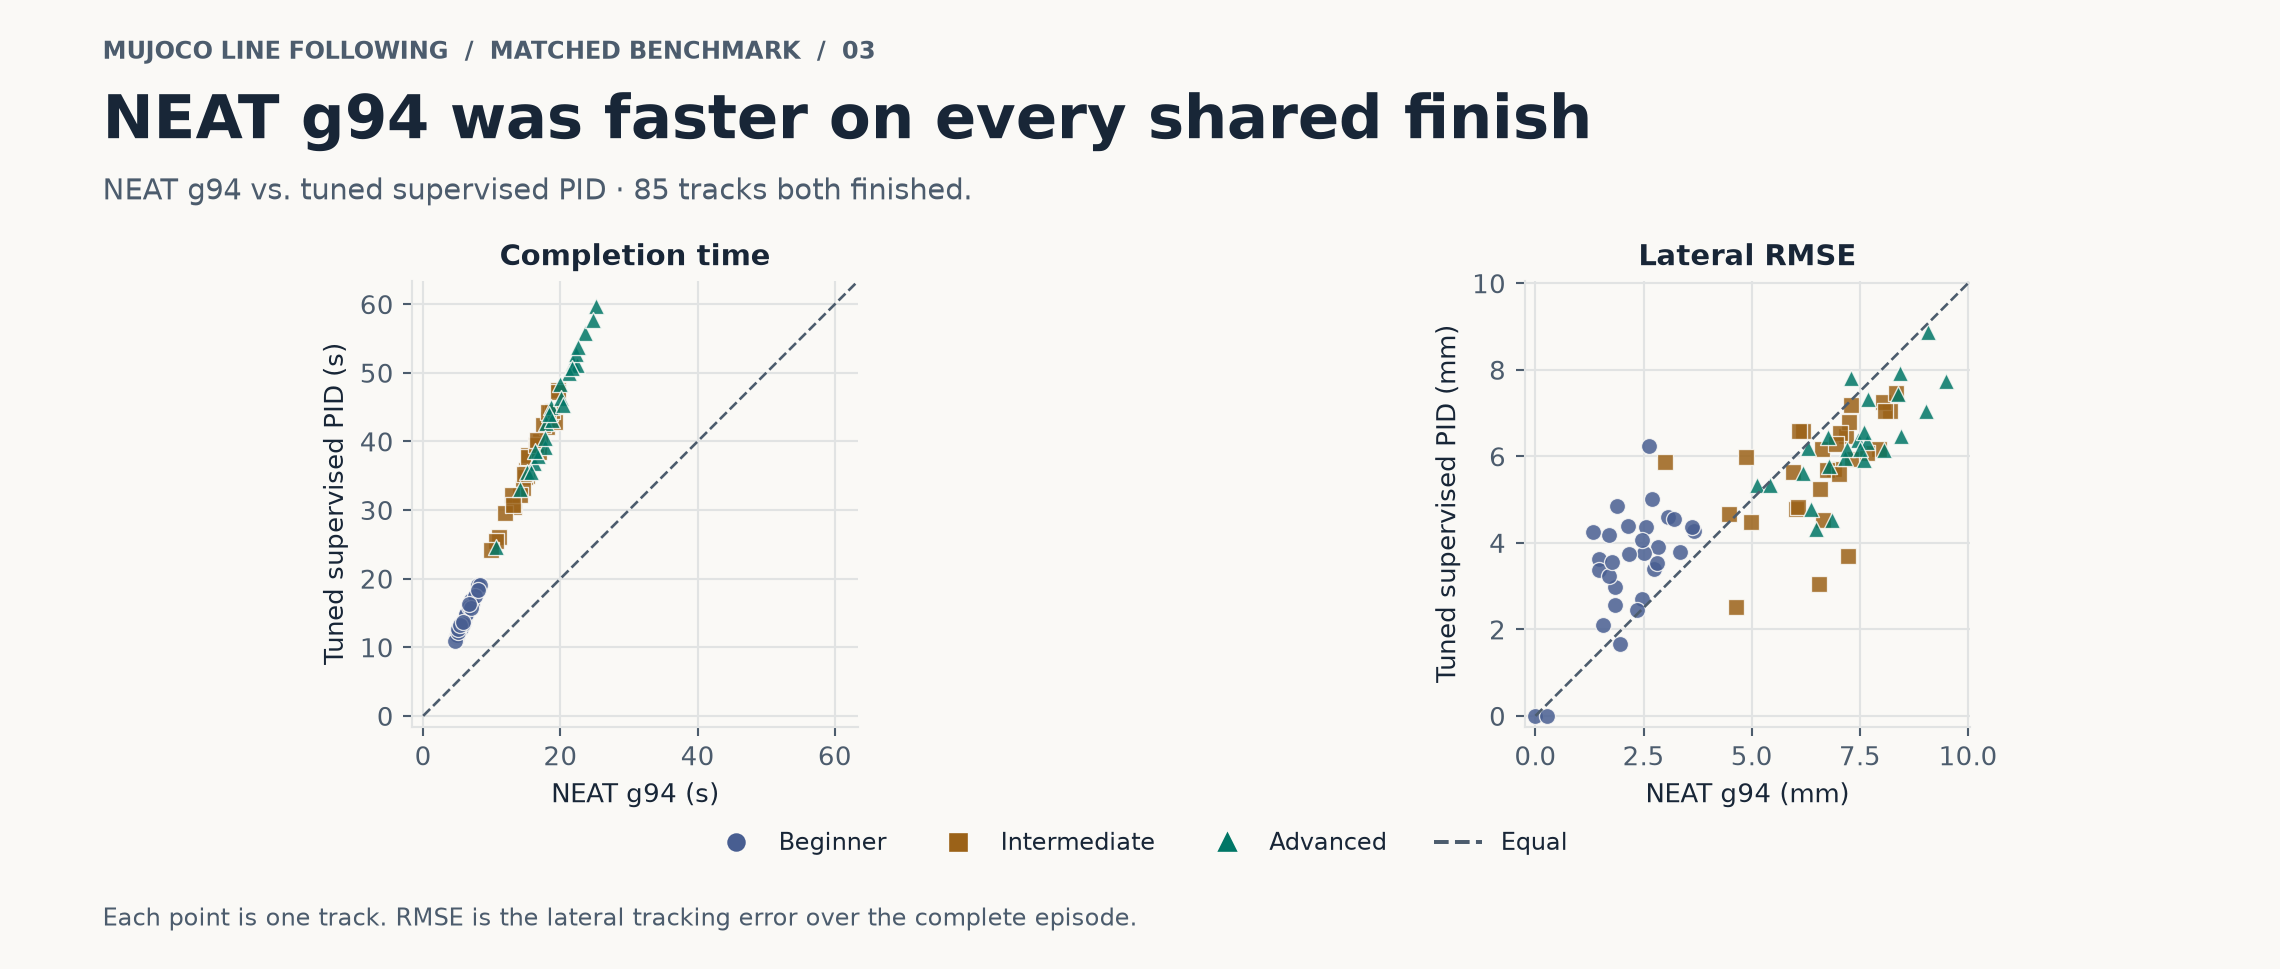

In [6]:
def paired_plot(rows):
    common = [(a, b) for a, b in zip(rows["neat-fresh"], rows["pid-supervised-tuned"], strict=True)
              if completed(a) and completed(b)]
    fig = page(3, "NEAT g94 was faster on every shared finish",
               f"NEAT g94 vs. tuned supervised PID · {len(common)} tracks both finished.",
               "Each point is one track. RMSE is the lateral tracking error over the complete episode.")
    axes = fig.add_gridspec(1, 2, left=.085, right=.96, top=.71, bottom=.25, wspace=.26).subplots()
    difficulty = list(zip(LEVELS, ("o", "s", "^"), ("#485e91", "#9b6218", "#007666")))
    for ax, field, title, units, scale in zip(axes, ("completion_time_s", "lateral_rmse_m"),
                                              ("Completion time", "Lateral RMSE"), ("s", "mm"), (1, 1000)):
        max_value = max(float(row[field])*scale for pair in common for row in pair) * 1.06
        ax.plot([0, max_value], [0, max_value], color=MUTED, ls="--", lw=1)
        for level, marker, color in difficulty:
            subset = [(a, b) for a, b in common if a["difficulty"] == level]
            ax.scatter([float(a[field])*scale for a, _ in subset], [float(b[field])*scale for _, b in subset],
                       color=color, marker=marker, s=37, alpha=.85, edgecolor=PAPER, linewidth=.5)
        limits = (-.025*max_value, max_value)
        ax.set(title=title, xlabel=f"NEAT g94 ({units})", ylabel=f"Tuned supervised PID ({units})",
               xlim=limits, ylim=limits, aspect="equal")
        ax.grid(color=GRID)
        ax.set_axisbelow(True)
    handles = [Line2D([], [], marker=m, color=c, ls="", label=d.title()) for d, m, c in difficulty]
    handles.append(Line2D([], [], color=MUTED, ls="--", label="Equal"))
    fig.legend(handles=handles, ncol=4, loc="lower center", bbox_to_anchor=(.5, .095), frameon=False, fontsize=9)
    save(fig, "03-paired-speed-error")

paired_plot(rows)

## 4. Zigzag trajectories

The top panels overlay chassis positions on the actual paint masks from test slots 031 and 032. The bottom panels plot route progress against simulated time for those same runs. Both examples are illustrative traces from the frozen benchmark.

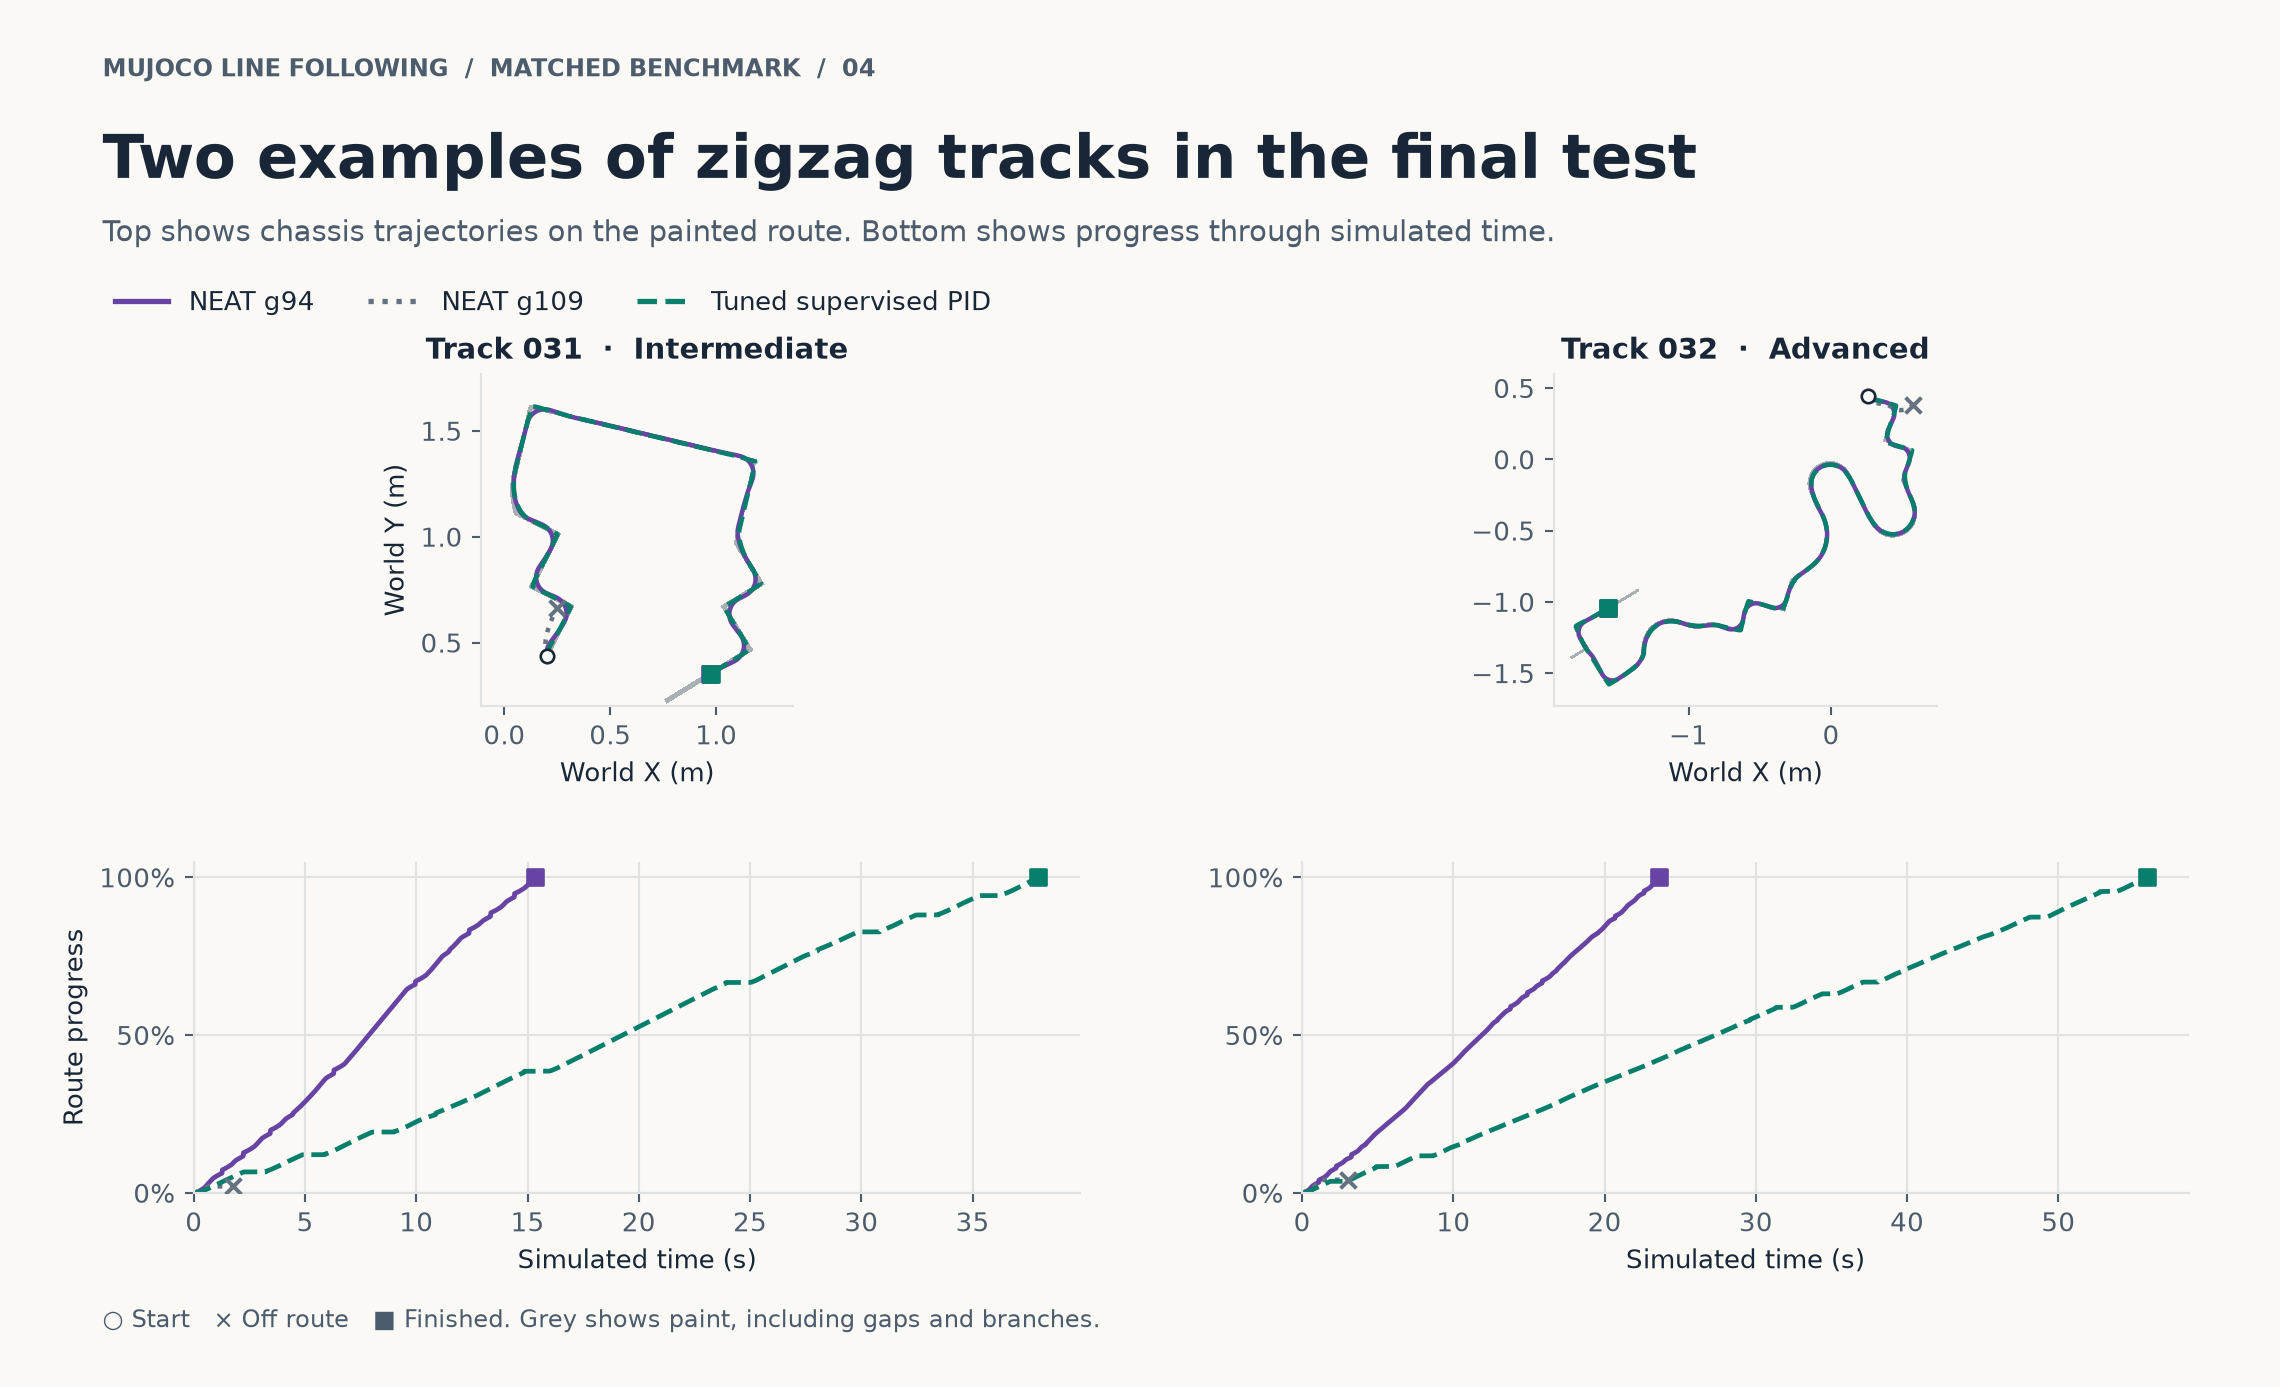

In [7]:
def trace_plot(rows, example_tracks):
    fig = page(4, "Two examples of zigzag tracks in the final test",
               "Top shows chassis trajectories on the painted route. Bottom shows progress through simulated time.",
               "○ Start   × Off route   ■ Finished. Grey shows paint, including gaps and branches.", size=(12, 7.3))
    axes = fig.add_gridspec(2, 2, left=.085, right=.96, top=.73, bottom=.14, hspace=.47, wspace=.25).subplots()
    policies = ("neat-fresh", "neat-g109", "pid-supervised-tuned")
    styles = ("-", ":", "--")
    for column, slot in enumerate((31, 32)):
        track = example_tracks[str(slot)]
        xy, clock = axes[:, column]
        half = track["arena_size"] / 2
        paint = np.asarray(PILImage.open(BytesIO(base64.b64decode(track["paint"]))))
        xy.imshow(paint, cmap=ListedColormap(["#a8afb5", PAPER]),
                  extent=(-half, half, -half, half), interpolation="nearest", vmin=0, vmax=255)
        points = [np.asarray(track["bounds"])]
        for policy, style in zip(policies, styles):
            row = rows[policy][slot]
            t, x, y, progress = np.asarray(track["traces"][policy]).T
            assert len(t) == int(row["control_steps"]) and np.isclose(t[-1], float(row["elapsed_s"]))
            color = POLICIES[policy][1]
            marker = "s" if completed(row) else "x"
            xy.plot(x, y, color=color, ls=style, lw=1.7)
            xy.scatter(x[-1], y[-1], color=color, marker=marker, s=36, zorder=4)
            clock.plot(np.r_[0, t], np.r_[0, progress*100], color=color, ls=style, lw=1.8)
            clock.scatter(t[-1], progress[-1]*100, color=color, marker=marker, s=36, zorder=4)
            points.append(np.column_stack((x, y)))
        x, y = np.concatenate(points).T
        xy.scatter(*track["start"], facecolor=PAPER, edgecolor=INK, s=26, zorder=5)
        xy.set(title=f"Track {slot:03}  ·  {track['difficulty'].title()}", xlabel="World X (m)",
               xlim=(min(x)-.15, max(x)+.15), ylim=(min(y)-.15, max(y)+.15), aspect="equal")
        clock.set(xlabel="Simulated time (s)", xlim=(0, None), ylim=(0, 105), yticks=(0, 50, 100))
        clock.yaxis.set_major_formatter(PercentFormatter(100))
        clock.grid(color=GRID)
    axes[0, 0].set_ylabel("World Y (m)")
    axes[1, 0].set_ylabel("Route progress")
    handles = [Line2D([], [], ls=style, lw=2, color=POLICIES[p][1], label=POLICIES[p][0])
               for p, style in zip(policies, styles)]
    fig.legend(handles=handles, ncol=3, loc="upper left", bbox_to_anchor=(.04, .808), frameon=False)
    save(fig, "04-zigzag-traces")

trace_plot(rows, example_tracks)